In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
data = pd.read_csv("mall.csv")
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
data.shape

(200, 5)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [7]:
data.isnull().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [8]:
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [9]:
x = data[["Annual Income (k$)", "Spending Score (1-100)"]]
x.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [10]:
from sklearn.cluster import KMeans

In [11]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(x)
    wcss.append(model.inertia_)

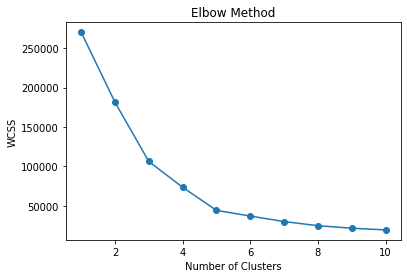

In [12]:
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [13]:
k = 5
model = KMeans(n_clusters=k, random_state=42, n_init=10)
data["KMeans_Cluster"] = model.fit_predict(x)
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),KMeans_Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,3
2,3,Female,20,16,6,2
3,4,Female,23,16,77,3
4,5,Female,31,17,40,2


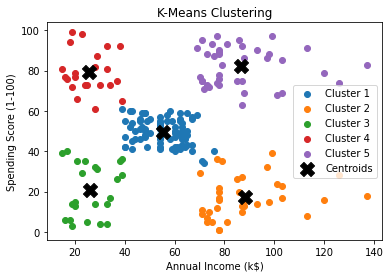

In [14]:
for i in range(k):
    plt.scatter(
        x["Annual Income (k$)"][data["KMeans_Cluster"] == i],
        x["Spending Score (1-100)"][data["KMeans_Cluster"] == i],
        label=f"Cluster {i+1}"
    )

centroids = model.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200,
    c="black",
    edgecolors="black",
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

In [15]:
data.groupby("KMeans_Cluster")[["Annual Income (k$)", "Spending Score (1-100)"]].mean()

,Annual Income (k$),Spending Score (1-100)
KMeans_Cluster,,
0,55.296296,49.518519
1,88.200000,17.114286
2,26.304348,20.913043
3,25.727273,79.363636
4,86.538462,82.128205


In [16]:
annual_income = float(input("Enter Annual Income (k$): "))
spending_score = float(input("Enter Spending Score (1-100): "))

new_customer = pd.DataFrame(
    [[annual_income, spending_score]],
    columns=["Annual Income (k$)", "Spending Score (1-100)"]
)

predicted_cluster = model.predict(new_customer)
print("Predicted Cluster:", predicted_cluster[0] + 1)

Enter Annual Income (k$): 7778878
Enter Spending Score (1-100): 78
Predicted Cluster: 2


In [17]:
from scipy.cluster.hierarchy import dendrogram, linkage

link = linkage(x, method="ward")

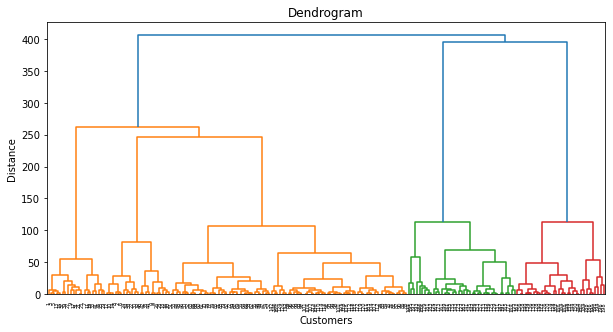

In [18]:
plt.figure(figsize=(10, 5))
dendrogram(link)
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()

In [19]:
from sklearn.cluster import AgglomerativeClustering

h_model = AgglomerativeClustering(n_clusters=k)
data["Hierarchical_Cluster"] = h_model.fit_predict(x)
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),KMeans_Cluster,Hierarchical_Cluster
0,1,Male,19,15,39,2,4
1,2,Male,21,15,81,3,3
2,3,Female,20,16,6,2,4
3,4,Female,23,16,77,3,3
4,5,Female,31,17,40,2,4


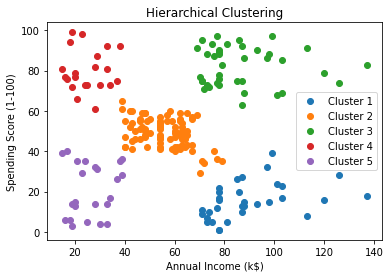

In [20]:
for i in range(k):
    plt.scatter(
        x["Annual Income (k$)"][data["Hierarchical_Cluster"] == i],
        x["Spending Score (1-100)"][data["Hierarchical_Cluster"] == i],
        label=f"Cluster {i+1}"
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Hierarchical Clustering")
plt.legend()
plt.show()

In [21]:
data.groupby("Hierarchical_Cluster")[["Annual Income (k$)", "Spending Score (1-100)"]].mean()

,Annual Income (k$),Spending Score (1-100)
Hierarchical_Cluster,,
0,89.406250,15.593750
1,55.811765,49.129412
2,86.538462,82.128205
3,25.095238,80.047619
4,26.304348,20.913043


In [22]:
hc_means = x.groupby(data["Hierarchical_Cluster"]).mean()

annual_income = float(input("Enter Annual Income (k$): "))
spending_score = float(input("Enter Spending Score (1-100): "))
new_customer = np.array([annual_income, spending_score])

distances = np.sqrt(((hc_means.values - new_customer) ** 2).sum(axis=1))
cluster = hc_means.index[np.argmin(distances)]

print("Predicted Cluster:", cluster + 1)

Enter Annual Income (k$): 88888
Enter Spending Score (1-100): 78
Predicted Cluster: 1


In [23]:
hc_means = x.groupby(data["Hierarchical_Cluster"]).mean()

annual_income = float(input("Enter Annual Income (k$): "))
spending_score = float(input("Enter Spending Score (1-100): "))

new_customer = np.array([annual_income, spending_score])

distances = np.linalg.norm(hc_means.values - new_customer, axis=1)
cluster = hc_means.index[np.argmin(distances)]

print("Predicted Cluster:", cluster + 1)

Enter Annual Income (k$): 88888
Enter Spending Score (1-100): 78
Predicted Cluster: 1
